# Συσχέτιση μεταξύ των χαρακτηριστικών (ετερο-συσχέτιση) και τι σημαίνει για την πρόβλεψη
Ερωτήματα:
1. Πόσο συσχετίζονται τα χαρακτηριστικά εισόδου **μεταξύ τους** σε κάθε dataset;
2. Στο UNSW-NB15, μπορεί η ετικέτα να βγει με έναν **απλό κανόνα**, χωρίς μοντέλο;
3. Τι γίνεται αν **αφαιρέσουμε τα πλεονάζοντα** χαρακτηριστικά;

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

DATA, MODELS, FIG = "../data/", "../models/", "../figures/"
SEED = 42
CORR_CMAP = LinearSegmentedColormap.from_list("corr", ["#2a78d6", "#f1f0ec", "#eb6834"])

train = pd.read_csv(DATA + "UNSW_NB15_train-set.csv")
test = pd.read_csv(DATA + "UNSW_NB15_test-set.csv")
NUM = [c for c in train.columns if c not in ["id", "proto", "service", "state", "attack_cat", "label"]]

# ίδιος μετασχηματισμός με την προεπεξεργασία: log(1+x) στα πολύ ασύμμετρα χαρακτηριστικά
skewed = train[NUM].skew()[lambda s: s > 2].index
def transform(df):
    X = df[NUM].astype("float64").copy()
    X[skewed] = np.log1p(X[skewed])
    return X
X_train, X_test = transform(train), transform(test)

## 1. Πίνακας συσχέτισης των χαρακτηριστικών του UNSW-NB15
Συντελεστής Pearson για κάθε ζεύγος χαρακτηριστικών. Έντονο πορτοκαλί ή μπλε = τα δύο χαρακτηριστικά «λένε σχεδόν το ίδιο πράγμα».

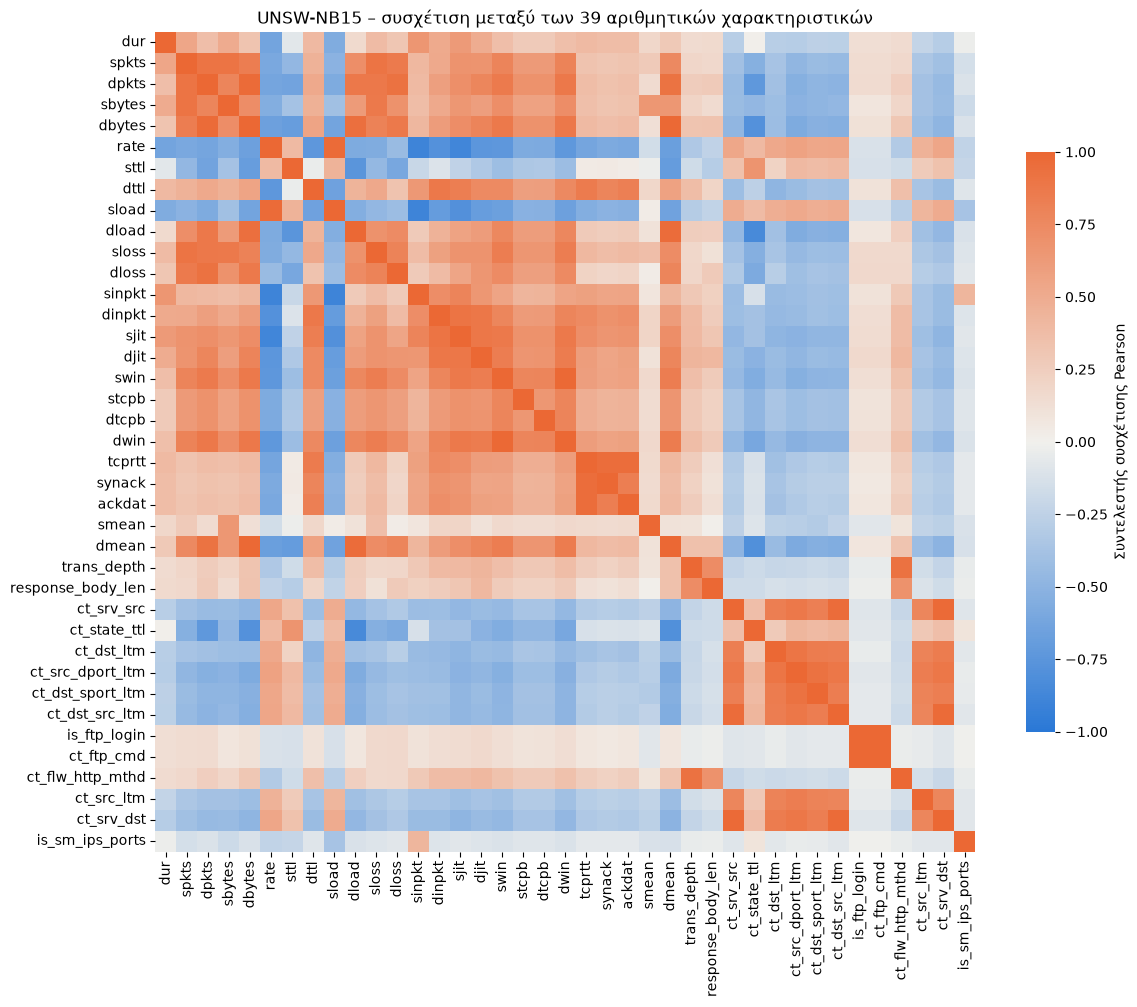

In [2]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap=CORR_CMAP, vmin=-1, vmax=1, center=0, square=True, ax=ax,
            cbar_kws={"shrink": 0.7, "label": "Συντελεστής συσχέτισης Pearson"})
ax.set_title("UNSW-NB15 – συσχέτιση μεταξύ των 39 αριθμητικών χαρακτηριστικών")
plt.tight_layout(); plt.savefig(FIG + "23_unsw_feature_correlation.png", dpi=200); plt.show()

In [3]:
def pair_summary(c, name):
    v = np.abs(c.values[np.triu_indices(len(c), 1)])
    return {"dataset": name, "χαρακτηριστικά": len(c), "ζεύγη": len(v), "|r| > 0.9": int((v > 0.9).sum()),
            "|r| > 0.8": int((v > 0.8).sum()), "|r| > 0.5": int((v > 0.5).sum()), "μέγιστο |r|": round(float(v.max()), 3)}

ct = pd.read_csv(DATA + "ctdapd_clean.csv", keep_default_na=False)
ci = pd.read_csv(DATA + "intrusion_clean.csv", keep_default_na=False)
ct_num = ["Flow_Duration", "Packet_Size", "Total_Forward_Packets", "Total_Backward_Packets", "IDS_Alert_Count", "Anomaly_Score"]
ci_num = ["network_packet_size", "login_attempts", "session_duration", "ip_reputation_score", "failed_logins", "unusual_time_access"]

summary = pd.DataFrame([pair_summary(corr, "UNSW-NB15"), pair_summary(ct[ct_num].corr(), "CTDAPD"),
                        pair_summary(ci[ci_num].corr(), "Intrusion")]).set_index("dataset")
print(summary.to_string())

absc = corr.abs()
pairs = [(NUM[i], NUM[j], round(absc.values[i, j], 3)) for i, j in zip(*np.triu_indices(len(NUM), 1)) if absc.values[i, j] > 0.9]
print("\nΖεύγη με |r| > 0.9 στο UNSW-NB15:")
print(pd.DataFrame(pairs, columns=["χαρακτηριστικό Α", "χαρακτηριστικό Β", "|r|"]).sort_values("|r|", ascending=False).to_string(index=False))

           χαρακτηριστικά  ζεύγη  |r| > 0.9  |r| > 0.8  |r| > 0.5  μέγιστο |r|
dataset                                                                       
UNSW-NB15              39    741         21         65        255        1.000
CTDAPD                  6     15          0          0          0        0.010
Intrusion               6     15          0          0          0        0.022

Ζεύγη με |r| > 0.9 στο UNSW-NB15:
χαρακτηριστικό Α χαρακτηριστικό Β   |r|
    is_ftp_login       ct_ftp_cmd 1.000
            swin             dwin 0.990
          dbytes            dmean 0.985
      ct_srv_src       ct_srv_dst 0.980
           dpkts           dbytes 0.973
            rate            sload 0.972
  ct_dst_src_ltm       ct_srv_dst 0.972
      ct_srv_src   ct_dst_src_ltm 0.967
           dload            dmean 0.964
          tcprtt           synack 0.959
          tcprtt           ackdat 0.953
          dbytes            dload 0.945
           dpkts            dloss 0.929
ct_src_dpo

## 2. Μπορεί η ετικέτα να βγει με έναν απλό κανόνα;
Αν η ετικέτα «προέκυπτε» άμεσα από τα χαρακτηριστικά, ένα δέντρο απόφασης με 1–3 ερωτήσεις θα έφτανε κοντά στο 100%.

In [4]:
y_train, y_test = train["label"], test["label"]
rules = {}
for f in ["sttl", "ct_state_ttl"]:
    m = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(X_train[[f]], y_train)
    rules[f"Κανόνας μόνο με το {f}"] = accuracy_score(y_test, m.predict(X_test[[f]]))
for depth in [1, 3, 5]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(X_train, y_train)
    rules[f"Δέντρο απόφασης βάθους {depth} (όλα τα χαρακτηριστικά)"] = accuracy_score(y_test, m.predict(X_test))
print(pd.Series(rules, name="accuracy στο test").round(4).to_string())

Κανόνας μόνο με το sttl                             0.7663
Κανόνας μόνο με το ct_state_ttl                     0.7934
Δέντρο απόφασης βάθους 1 (όλα τα χαρακτηριστικά)    0.7663
Δέντρο απόφασης βάθους 3 (όλα τα χαρακτηριστικά)    0.7670
Δέντρο απόφασης βάθους 5 (όλα τα χαρακτηριστικά)    0.8119


## 3. Αφαίρεση πλεοναζόντων χαρακτηριστικών
Από κάθε ομάδα χαρακτηριστικών με |r| > 0.9 κρατάμε μόνο ένα. Δοκιμάζουμε επίσης χωρίς τα χαρακτηριστικά TTL (`sttl`, `dttl`, `ct_state_ttl`),
που είναι γνωστό ότι στο UNSW-NB15 «προδίδουν» σε μεγάλο βαθμό την επίθεση. Το Random Forest χρησιμοποιείται εδώ ως γρήγορο μέτρο σύγκρισης (2–4 λεπτά).

In [5]:
keep = []
for c in NUM:
    if all(absc.loc[c, k] <= 0.9 for k in keep):
        keep.append(c)
dropped = [c for c in NUM if c not in keep]
TTL = ["sttl", "dttl", "ct_state_ttl"]
print(f"Κρατάμε {len(keep)} από {len(NUM)}. Αφαιρούνται: {dropped}")

variants = {"Όλα τα χαρακτηριστικά": NUM,
            "Χωρίς πλεονάζοντα (|r| ≤ 0.9)": keep,
            "Χωρίς TTL": [c for c in NUM if c not in TTL]}
rows = {}
for name, cols in variants.items():
    rf = lambda: RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
    p = rf().fit(X_train[cols], y_train).predict_proba(X_test[cols])[:, 1]
    pa = rf().fit(X_train[cols], train["attack_cat"]).predict(X_test[cols])
    rows[name] = {"πλήθος": len(cols), "label acc": accuracy_score(y_test, p >= 0.5), "label ROC-AUC": roc_auc_score(y_test, p),
                  "attack_cat acc": accuracy_score(test["attack_cat"], pa),
                  "attack_cat macro-F1": f1_score(test["attack_cat"], pa, average="macro")}
    print(name, "έτοιμο")
feat_table = pd.DataFrame(rows).T.round(4)
feat_table.to_csv(MODELS + "unsw_feature_redundancy.csv")
print(feat_table.to_string())

Κρατάμε 24 από 39. Αφαιρούνται: ['dpkts', 'sbytes', 'sload', 'dload', 'sloss', 'sjit', 'dwin', 'synack', 'ackdat', 'dmean', 'ct_src_dport_ltm', 'ct_dst_src_ltm', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_srv_dst']
Όλα τα χαρακτηριστικά έτοιμο
Χωρίς πλεονάζοντα (|r| ≤ 0.9) έτοιμο
Χωρίς TTL έτοιμο
                               πλήθος  label acc  label ROC-AUC  attack_cat acc  attack_cat macro-F1
Όλα τα χαρακτηριστικά            39.0     0.8686         0.9783          0.7476               0.5001
Χωρίς πλεονάζοντα (|r| ≤ 0.9)    24.0     0.8564         0.9713          0.7408               0.4669
Χωρίς TTL                        36.0     0.8667         0.9773          0.7454               0.4794


## 4. Πόσο αυστηρά να «καθαρίσουμε»; Σύγκριση κατωφλιών
Για κάθε κατώφλι κρατάμε χαρακτηριστικά έτσι ώστε κανένα ζεύγος να μην έχει |r| πάνω από το κατώφλι, και μετράμε τι χάνουμε σε επίδοση.
Με κατώφλι 0.5 δεν μένει **κανένα** ζεύγος με ισχυρή συσχέτιση. (3–6 λεπτά.)

In [6]:
def select_features(threshold):
    kept = []
    for c in NUM:
        if all(absc.loc[c, k] <= threshold for k in kept):
            kept.append(c)
    return kept

thr_rows, selected = {}, {}
for t in [1.0, 0.9, 0.8, 0.7, 0.5]:
    cols = select_features(t); selected[t] = cols
    v = absc.loc[cols, cols].values[np.triu_indices(len(cols), 1)]
    rf = lambda: RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
    p = rf().fit(X_train[cols], y_train).predict_proba(X_test[cols])[:, 1]
    pa = rf().fit(X_train[cols], train["attack_cat"]).predict(X_test[cols])
    thr_rows["όλα" if t == 1.0 else f"|r| ≤ {t}"] = {
        "χαρακτηριστικά": len(cols), "ζεύγη με |r| > 0.5": int((v > 0.5).sum()), "μέγιστο |r|": round(float(v.max()), 2),
        "label acc": round(accuracy_score(y_test, p >= 0.5), 4), "label ROC-AUC": round(roc_auc_score(y_test, p), 4),
        "attack_cat acc": round(accuracy_score(test["attack_cat"], pa), 4)}
thr_table = pd.DataFrame(thr_rows).T
thr_table.to_csv(MODELS + "unsw_feature_selection_thresholds.csv")
print(thr_table.to_string())
for t in [0.7, 0.5]:
    print(f"\nΧαρακτηριστικά με κατώφλι {t}: {selected[t]}")

           χαρακτηριστικά  ζεύγη με |r| > 0.5  μέγιστο |r|  label acc  label ROC-AUC  attack_cat acc
όλα                  39.0               255.0         1.00     0.8686         0.9783          0.7476
|r| ≤ 0.9            24.0                75.0         0.89     0.8564         0.9713          0.7408
|r| ≤ 0.8            17.0                28.0         0.79     0.8582         0.9695          0.7429
|r| ≤ 0.7            13.0                12.0         0.67     0.8558         0.9662          0.7391
|r| ≤ 0.5             8.0                 0.0         0.44     0.8565         0.9638          0.7288

Χαρακτηριστικά με κατώφλι 0.7: ['dur', 'spkts', 'rate', 'sttl', 'stcpb', 'dtcpb', 'tcprtt', 'smean', 'trans_depth', 'ct_srv_src', 'ct_state_ttl', 'is_ftp_login', 'is_sm_ips_ports']

Χαρακτηριστικά με κατώφλι 0.5: ['dur', 'dpkts', 'tcprtt', 'smean', 'trans_depth', 'ct_srv_src', 'is_ftp_login', 'is_sm_ips_ports']


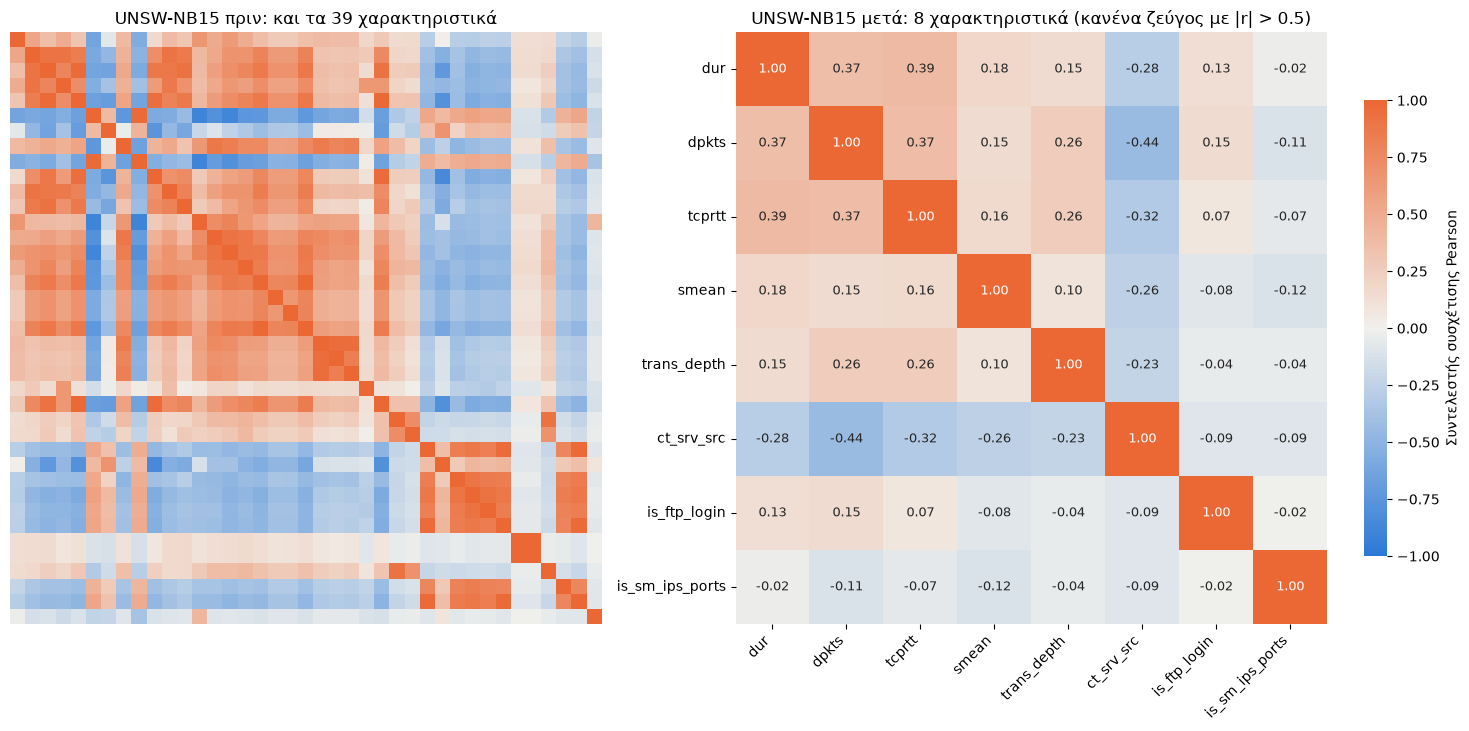

In [7]:
FINAL_T = 0.5
cols = selected[FINAL_T]
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 1.25]})
sns.heatmap(corr, cmap=CORR_CMAP, vmin=-1, vmax=1, center=0, square=True, cbar=False,
            xticklabels=False, yticklabels=False, ax=axes[0])
axes[0].set_title(f"UNSW-NB15 πριν: και τα {len(NUM)} χαρακτηριστικά")
sns.heatmap(corr.loc[cols, cols], cmap=CORR_CMAP, vmin=-1, vmax=1, center=0, square=True, annot=True, fmt=".2f",
            annot_kws={"size": 9}, cbar_kws={"shrink": 0.75, "label": "Συντελεστής συσχέτισης Pearson"}, ax=axes[1])
axes[1].set_title(f"UNSW-NB15 μετά: {len(cols)} χαρακτηριστικά (κανένα ζεύγος με |r| > {FINAL_T})")
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.savefig(FIG + "24_unsw_correlation_before_after.png", dpi=200, bbox_inches="tight"); plt.show()